Imports and configurations

In [35]:

import pandas as pd
import numpy as np
from pathlib import Path

# Project paths 
RAW_DATA = Path("../raw_data")
PROCESSED = Path("../processed")
PROCESSED.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 100)

Data Ingestion

In [36]:
train_transaction = pd.read_csv(RAW_DATA / "train_transaction.csv")
train_identity = pd.read_csv(RAW_DATA / "train_identity.csv")

print("Transaction shape:", train_transaction.shape)
print("Identity shape:", train_identity.shape)

Transaction shape: (590540, 394)
Identity shape: (144233, 41)


In [37]:
train_transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,M1,M2,M3,M4,...,V290,V291,V292,V293,V294,V295,V296,V297,V298,V299,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,1.0,14.0,NaN,13.0,NaN,NaN,NaN,NaN,NaN,NaN,13.0,13.0,NaN,NaN,NaN,0.0,T,T,T,M2,...,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,117.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,M0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,315.0,NaN,NaN,NaN,315.0,T,T,T,M0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,25.0,1.0,112.0,112.0,0.0,94.0,0.0,NaN,NaN,NaN,NaN,84.0,NaN,NaN,NaN,NaN,111.0,NaN,NaN,NaN,M0,...,1.0,1.0,1.0,1.0,38.0,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,50.0,1758.0,925.0,0.0,354.0,0.0,135.0,0.0,0.0,0.0,50.0,1404.0,790.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [38]:
train_identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,NotFound,NaN,-480.0,New,NotFound,166.0,NaN,542.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,NaN,100.0,NotFound,49.0,-300.0,New,NotFound,166.0,NaN,621.0,500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,iOS 11.1.2,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,100.0,NotFound,52.0,NaN,Found,Found,121.0,NaN,410.0,142.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,NaN,100.0,NotFound,52.0,NaN,New,NotFound,225.0,NaN,176.0,507.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,0.0,100.0,NotFound,NaN,-300.0,Found,Found,166.0,15.0,529.0,575.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,Mac OS X 10_11_6,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


Merge the data

In [39]:
df = train_transaction.merge(train_identity, on="TransactionID", how="left")

print("Merged shape:", df.shape)
print("Fraud rate:", df["isFraud"].mean())

Merged shape: (590540, 434)
Fraud rate: 0.03499000914417313


In [40]:
df.to_parquet(PROCESSED / "data_merged.parquet", index=False)

Missing values Inspection

In [41]:
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_report = missing_pct[missing_pct > 0].reset_index()
missing_report.columns = ["column", "missing_pct"]

print(f"Columns with missings: {len(missing_report)} de {df.shape[1]}")
missing_report.head(20)

Columns with missings: 414 de 434


,column,missing_pct
0,id_24,99.196159
1,id_25,99.130965
2,id_07,99.127070
3,id_08,99.127070
4,id_21,99.126393
5,id_26,99.125715
6,id_27,99.124699
7,id_23,99.124699
8,id_22,99.124699
9,dist2,93.628374


Severity missing values distribution by column

severity
0-10%       92
10-30%      90
30-50%      18
50-70%       6
70-90%     196
90-100%     12
Name: count, dtype: int64


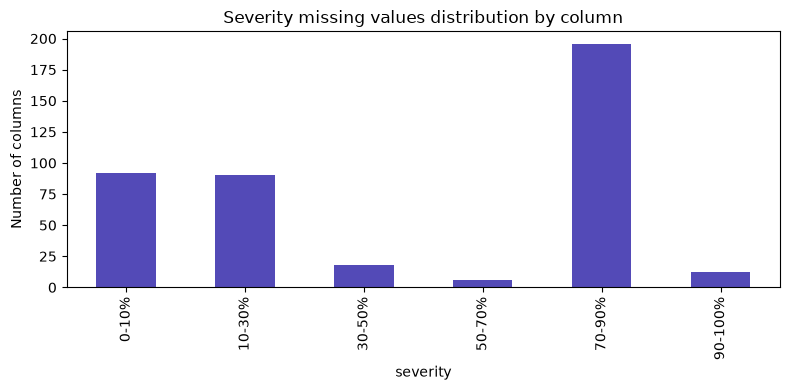

In [42]:
import matplotlib.pyplot as plt

bins = [0, 10, 30, 50, 70, 90, 100]
labels = ["0-10%", "10-30%", "30-50%", "50-70%", "70-90%", "90-100%"]
missing_report["severity"] = pd.cut(missing_report["missing_pct"], bins=bins, labels=labels)

severity_counts = missing_report["severity"].value_counts().sort_index()
print(severity_counts)

severity_counts.plot(kind="bar", figsize=(8,4), color="#534AB7")
plt.title("Severity missing values distribution by column")
plt.ylabel("Number of columns")
plt.tight_layout()
plt.savefig("../figures/missing_severity.png", dpi=150)
plt.show()

In [43]:
# High-missing columns (70-90%) - likely identity-related or conditional V features
high_missing = missing_report[missing_report["missing_pct"].between(70, 90)]["column"].tolist()
print("Examples of columns with 70-90% missing:")
print(high_missing[:15])

# Reasonably complete columns
low_missing = missing_report[missing_report["missing_pct"] < 30]["column"].tolist()
print("\nExamples of columns with <30% missing:")
print(low_missing[:15])

Examples of columns with 70-90% missing:
['D13', 'D14', 'D12', 'id_03', 'id_04', 'D6', 'id_33', 'id_10', 'id_09', 'D9', 'D8', 'id_30', 'id_32', 'id_34', 'id_14']

Examples of columns with <30% missing:
['M6', 'V35', 'V40', 'V41', 'V39', 'V38', 'V51', 'V37', 'V52', 'V36', 'V50', 'V48', 'V42', 'V43', 'V44']


In [44]:
# Classify high-missing columns by prefix/family
id_cols_high_missing = [c for c in high_missing if c.startswith("id_")]
d_cols_high_missing = [c for c in high_missing if c.startswith("D") and c not in ["DeviceInfo", "DeviceType"]]
other_high_missing = [c for c in high_missing if c not in id_cols_high_missing + d_cols_high_missing]

print(f"id_ columns (identity-related): {len(id_cols_high_missing)}")
print(f"D columns (time-delta features): {len(d_cols_high_missing)}")
print(f"Other high-missing columns: {len(other_high_missing)}")
print("\nOther columns (need individual review):", other_high_missing)

import json

missing_strategy = {
    "identity_related": id_cols_high_missing,
    "time_delta": d_cols_high_missing,
    "other_high_missing": other_high_missing
}

with open(PROCESSED / "missing_strategy.json", "w") as f:
    json.dump(missing_strategy, f, indent=2)


id_ columns (identity-related): 28
D columns (time-delta features): 6
Other high-missing columns: 162

Other columns (need individual review): ['V142', 'V158', 'V140', 'V162', 'V141', 'V161', 'V157', 'V146', 'V156', 'V155', 'V154', 'V153', 'V149', 'V147', 'V148', 'V163', 'V139', 'V138', 'V160', 'V151', 'V152', 'V145', 'V144', 'V143', 'V159', 'V164', 'V165', 'V166', 'V150', 'V337', 'V333', 'V336', 'V335', 'V334', 'V338', 'V339', 'V324', 'V332', 'V325', 'V330', 'V329', 'V328', 'V327', 'V326', 'V322', 'V323', 'V331', 'DeviceInfo', 'V278', 'V277', 'V252', 'V253', 'V254', 'V257', 'V258', 'V242', 'V261', 'V262', 'V263', 'V264', 'V249', 'V266', 'V267', 'V268', 'V269', 'V273', 'V274', 'V275', 'V276', 'V265', 'V260', 'V247', 'V246', 'V240', 'V237', 'V236', 'V235', 'V233', 'V232', 'V231', 'V230', 'V229', 'V228', 'V226', 'V225', 'V224', 'V223', 'V219', 'V218', 'V217', 'V243', 'V244', 'V248', 'V241', 'R_emaildomain', 'V212', 'V211', 'V214', 'V213', 'V196', 'V205', 'V183', 'V216', 'V206', 'V186', '

In [45]:
# Final column classification based on missingness analysis
v_conditional_cols = [c for c in other_high_missing if c.startswith("V")]
non_v_other = [c for c in other_high_missing if not c.startswith("V")]

print(f"V conditional-block columns: {len(v_conditional_cols)}")
print(f"Other non-V columns: {non_v_other}")

missing_strategy = {
    "identity_related": id_cols_high_missing,       
    "time_delta": d_cols_high_missing,                
    "v_conditional_blocks": v_conditional_cols,       
    "categorical_other": non_v_other                  
}

with open(PROCESSED / "missing_strategy.json", "w") as f:
    json.dump(missing_strategy, f, indent=2)

print("\nFinal missing_strategy.json saved for notebook 03.")

V conditional-block columns: 159
Other non-V columns: ['DeviceInfo', 'R_emaildomain', 'DeviceType']

Final missing_strategy.json saved for notebook 03.


## Summary

- Merged `train_transaction` (590,540 rows × 393 cols) with `train_identity` 
  (144,233 rows × 41 cols) on `TransactionID` using a left join.
- Final merged dataset: 590,540 rows × 434 columns.
- Overall fraud rate: 3.50% (moderate class imbalance, handled via class 
  weighting rather than oversampling).
- 414 of 434 columns contain missing values. Missingness is not random:
  - `id_*` columns (28): missing when no identity-verification data exists 
    for that transaction.
  - `D*` time-delta columns (8): missing when there's no prior event to 
    measure (e.g., first use of a card).
  - `V*` columns (159): missing in large consistent blocks — Vesta computes 
    these conditionally based on transaction type.
- Missingness will be preserved as a signal (via flags and a sentinel value 
  of -999) rather than imputed away, since it likely correlates with fraud 
  risk. This strategy is implemented in `03_feature_engineering.ipynb`.

Outputs: `data_merged.parquet`, `missing_report.csv`, `missing_strategy.json`